<a href="https://colab.research.google.com/github/kaviyaprab28/Genetic-Disorder-Risk-Assessment-System/blob/main/Genetic_Disorder_Risk_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Step 1 — Import libraries and load dataset**

In [ ]:
# STEP 1: IMPORT LIBRARIES AND LOAD DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
from sklearn.model_selection import GridSearchCV

# Upload training dataset
uploaded = files.upload()

# Find the training CSV
train_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
    and "train" in name.lower()
]

if not train_files:
    raise ValueError("Upload train_genetic_disorders.csv")

# Load dataset
df = pd.read_csv(train_files[0])
df.columns = df.columns.str.strip()

# Verify required target column
if "Genetic Disorder" not in df.columns:
    raise ValueError("Genetic Disorder target column is missing.")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Target column: Genetic Disorder")

display(df.head())

**Step 2 — Data cleaning and missing values**

In [ ]:
# STEP 2: DATA CLEANING

data = df.copy()

# Replace common missing-value markers
data.replace(
    ["", " ", "NA", "N/A", "Unknown", "Not Available", "?"],
    np.nan,
    inplace=True
)

# Treat -99 as missing where it represents an invalid value
data.replace([-99, "-99"], np.nan, inplace=True)

# Remove duplicate rows
print("Duplicate rows:", data.duplicated().sum())
data.drop_duplicates(inplace=True)

# Check missing values
print("\nMissing values:")
print(data.isnull().sum().sort_values(ascending=False))

# Remove rows without the target label
missing_targets = data["Genetic Disorder"].isnull().sum()
data.dropna(subset=["Genetic Disorder"], inplace=True)

print("\nMissing target rows removed:", missing_targets)
print("Cleaned dataset shape:", data.shape)

print("\nTarget categories:")
print(data["Genetic Disorder"].value_counts())

Duplicate rows: 1071

Missing values:
Family Name                                         9241
Mother's age                                        5719
Father's age                                        5690
Institute Name                                      4861
Autopsy shows birth defect (if applicable)          4165
Maternal gene                                       2695
Symptom 2                                           2113
H/O substance abuse                                 2091
Test 5                                              2073
Follow-up                                           2071
Disorder Subclass                                   2069
History of anomalies in previous pregnancies        2067
Gender                                              2064
Respiratory Rate (breaths/min)                      2060
Birth asphyxia                                      2059
Symptom 1                                           2057
Symptom 5                                         

**Step 3 — EDA and graphs**

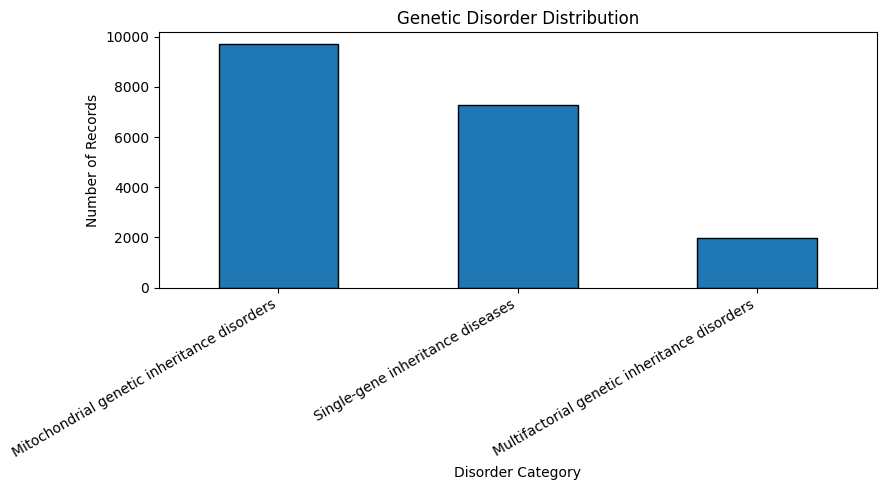

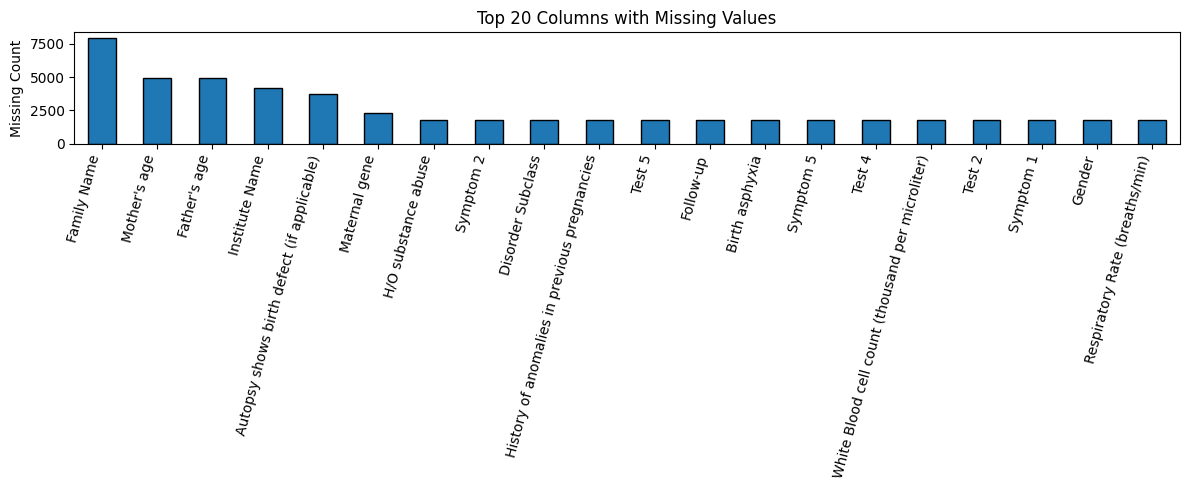

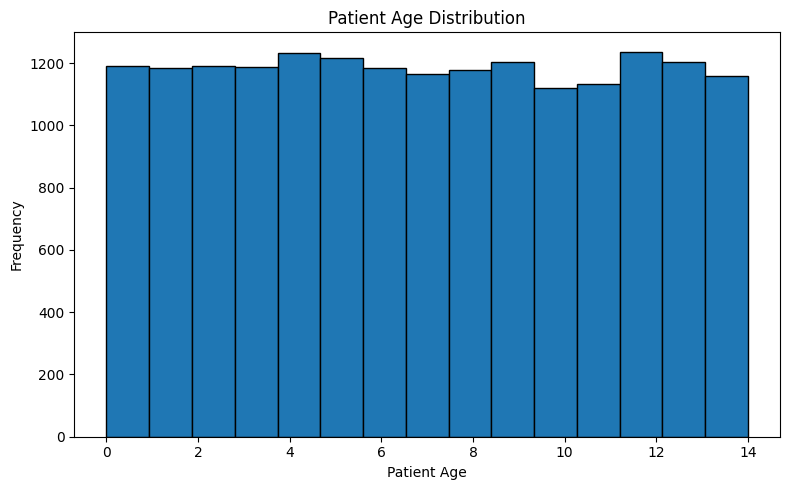

In [ ]:
# STEP 3: EXPLORATORY DATA ANALYSIS

# Graph 1: Target distribution
plt.figure(figsize=(9, 5))
data["Genetic Disorder"].value_counts().plot(
    kind="bar", edgecolor="black"
)
plt.title("Genetic Disorder Distribution")
plt.xlabel("Disorder Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Graph 2: Missing values
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False).head(20)

if len(missing) > 0:
    plt.figure(figsize=(12, 5))
    missing.plot(kind="bar", edgecolor="black")
    plt.title("Top 20 Columns with Missing Values")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

# Graph 3: Patient age distribution
if "Patient Age" in data.columns:
    age = pd.to_numeric(data["Patient Age"], errors="coerce")

    plt.figure(figsize=(8, 5))
    age.dropna().plot(kind="hist", bins=15, edgecolor="black")
    plt.title("Patient Age Distribution")
    plt.xlabel("Patient Age")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

**Step 4 — Select features and target**

In [ ]:
# STEP 4: FEATURE SELECTION

# Remove identifiers and related target information
columns_to_drop = [
    "Patient Id",
    "Patient First Name",
    "Family Name",
    "Father's name",
    "Institute Name",
    "Location of Institute",
    "Disorder Subclass",
    "Status"
]

columns_to_drop = [
    col for col in columns_to_drop
    if col in data.columns
]

data = data.drop(columns=columns_to_drop)

# Separate input features and target
X = data.drop(columns=["Genetic Disorder"]).copy()
y = data["Genetic Disorder"].astype(str).copy()

print("Removed columns:", columns_to_drop)
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget categories:")
print(y.value_counts())

Removed columns: ['Patient Id', 'Patient First Name', 'Family Name', "Father's name", 'Institute Name', 'Location of Institute', 'Disorder Subclass', 'Status']
Input features shape: (18962, 36)
Target shape: (18962,)

Target categories:
Genetic Disorder
Mitochondrial genetic inheritance disorders     9686
Single-gene inheritance diseases                7291
Multifactorial genetic inheritance disorders    1985
Name: count, dtype: int64


**Step 5 — Split the dataset**

In [ ]:
# STEP 5: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 15169
Testing records: 3793


**Step 6 — Preprocessing and encoding**

In [ ]:
# STEP 6: HANDLE MISSING VALUES AND ENCODE CATEGORIES

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical missing values: median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical missing values: most frequent value
# Then convert text categories to numeric columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_columns),
        ("categorical", categorical_transformer, categorical_columns)
    ]
)

print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))
print("Preprocessing pipeline created successfully!")

Numerical features: 16
Categorical features: 20
Preprocessing pipeline created successfully!


**Step 7 — Train the Decision Tree**

In [ ]:
# STEP 7: TRAIN BASELINE DECISION TREE

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Predict training and testing data
train_pred = baseline_model.predict(X_train)
test_pred = baseline_model.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print(
    "Accuracy Gap:",
    round((train_accuracy - test_accuracy) * 100, 2),
    "%"
)

Training Accuracy: 100.0 %
Testing Accuracy: 48.67 %
Accuracy Gap: 51.33 %


**Step 8 — Evaluate the model**

Classification Report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.58      0.57      0.58      1938
Multifactorial genetic inheritance disorders       0.27      0.28      0.28       397
            Single-gene inheritance diseases       0.42      0.43      0.42      1458

                                    accuracy                           0.49      3793
                                   macro avg       0.43      0.43      0.43      3793
                                weighted avg       0.49      0.49      0.49      3793



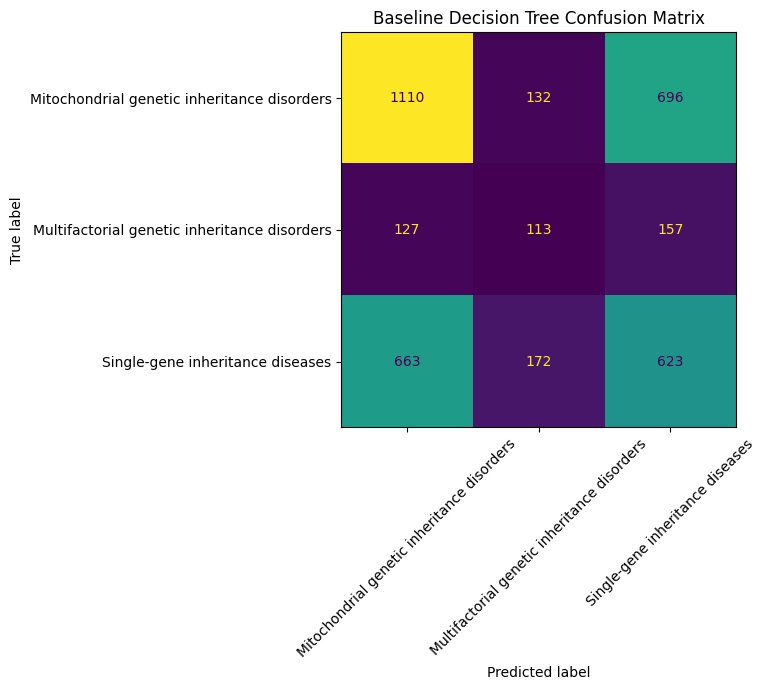

In [ ]:
# STEP 8: MODEL EVALUATION

print("Classification Report:")
print(classification_report(
    y_test,
    test_pred,
    zero_division=0
))

# Confusion matrix
labels = baseline_model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Baseline Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

**Step 9 — Tune parameters and reduce overfitting**

In [ ]:
# STEP 9: HYPERPARAMETER TUNING

tuning_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "classifier__max_depth": [4, 8, 12, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=tuning_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print(
    "Best cross-validation Macro F1:",
    round(grid_search.best_score_, 4)
)

Best parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}
Best cross-validation Macro F1: 0.4982


**Step 10 — Compare baseline and tuned models**

In [ ]:
# STEP 10: COMPARE MODEL PERFORMANCE

best_train_pred = best_model.predict(X_train)
best_test_pred = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Baseline Decision Tree", "Tuned Decision Tree"],
    "Training Accuracy (%)": [
        accuracy_score(y_train, train_pred) * 100,
        accuracy_score(y_train, best_train_pred) * 100
    ],
    "Testing Accuracy (%)": [
        accuracy_score(y_test, test_pred) * 100,
        accuracy_score(y_test, best_test_pred) * 100
    ],
    "Testing Macro F1": [
        f1_score(y_test, test_pred, average="macro", zero_division=0),
        f1_score(y_test, best_test_pred, average="macro", zero_division=0)
    ]
})

display(comparison.round(3))

print("\nTuned model classification report:")
print(classification_report(
    y_test,
    best_test_pred,
    zero_division=0
))

,Model,Training Accuracy (%),Testing Accuracy (%),Testing Macro F1
0,Baseline Decision Tree,100.00,48.669,0.427
1,Tuned Decision Tree,63.57,59.452,0.516



Tuned model classification report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.65      0.75      0.69      1938
Multifactorial genetic inheritance disorders       0.44      0.30      0.35       397
            Single-gene inheritance diseases       0.53      0.47      0.50      1458

                                    accuracy                           0.59      3793
                                   macro avg       0.54      0.51      0.52      3793
                                weighted avg       0.58      0.59      0.58      3793



**Step 11 — Visualize the Decision Tree**

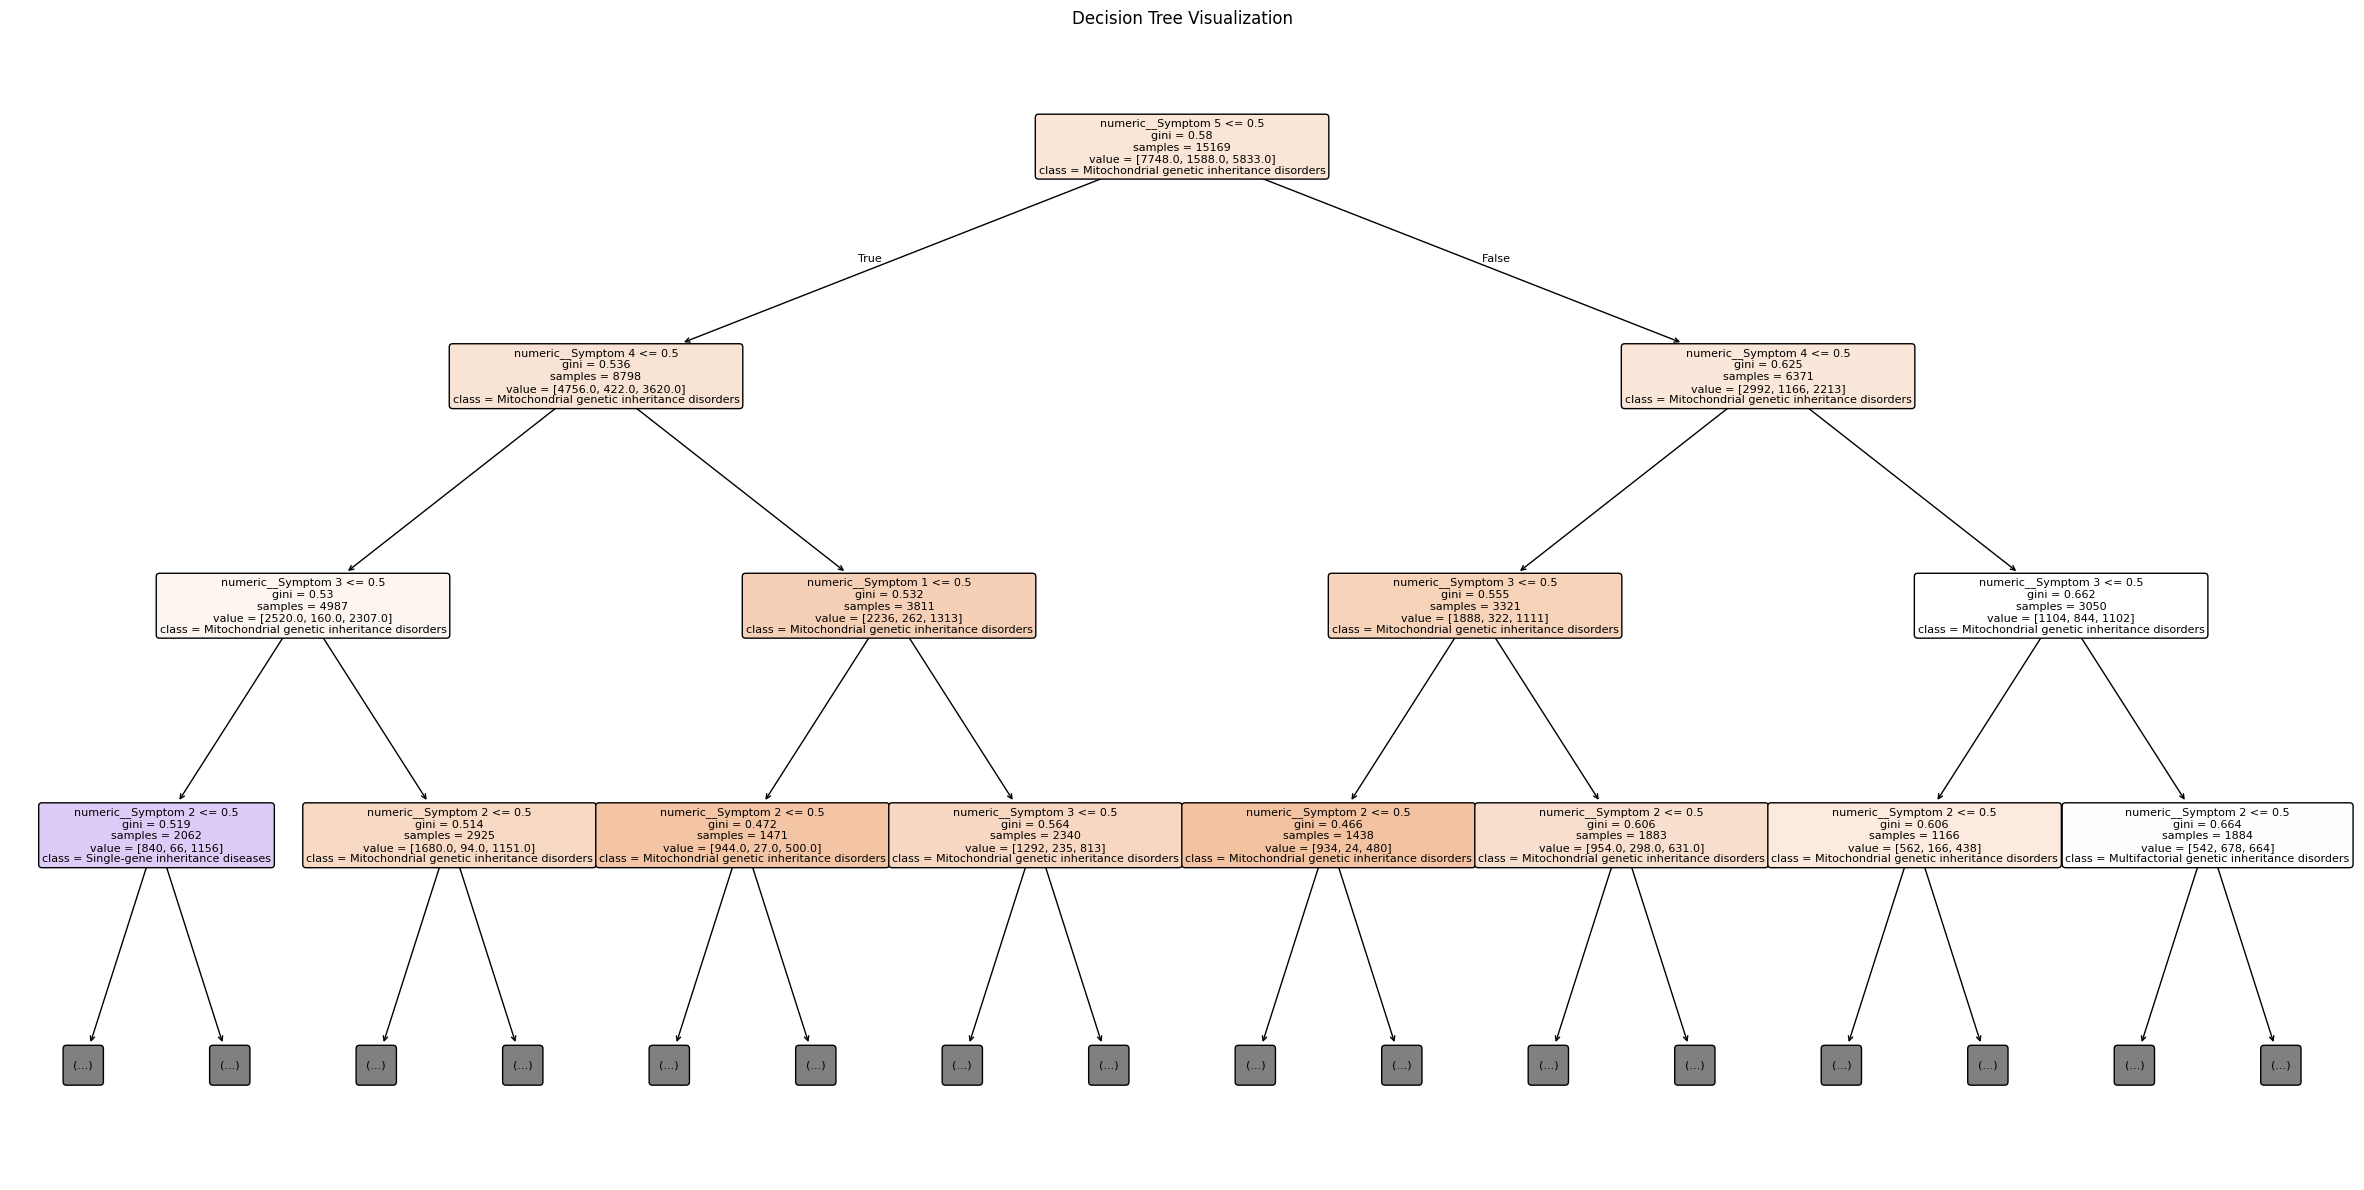

In [ ]:
# STEP 11: DECISION TREE VISUALIZATION

trained_tree = best_model.named_steps["classifier"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    trained_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=[str(c) for c in trained_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 12 — Feature importance**

Top 15 important features:


,Feature,Importance
12,numeric__Symptom 2,0.137890
13,numeric__Symptom 3,0.124291
11,numeric__Symptom 1,0.100639
14,numeric__Symptom 4,0.097210
15,numeric__Symptom 5,0.058660
10,numeric__White Blood cell count (thousand per ...,0.048925
16,categorical__Genes in mother's side_No,0.044944
18,categorical__Inherited from father_No,0.042054
1,numeric__Blood cell count (mcL),0.040226
17,categorical__Genes in mother's side_Yes,0.038800


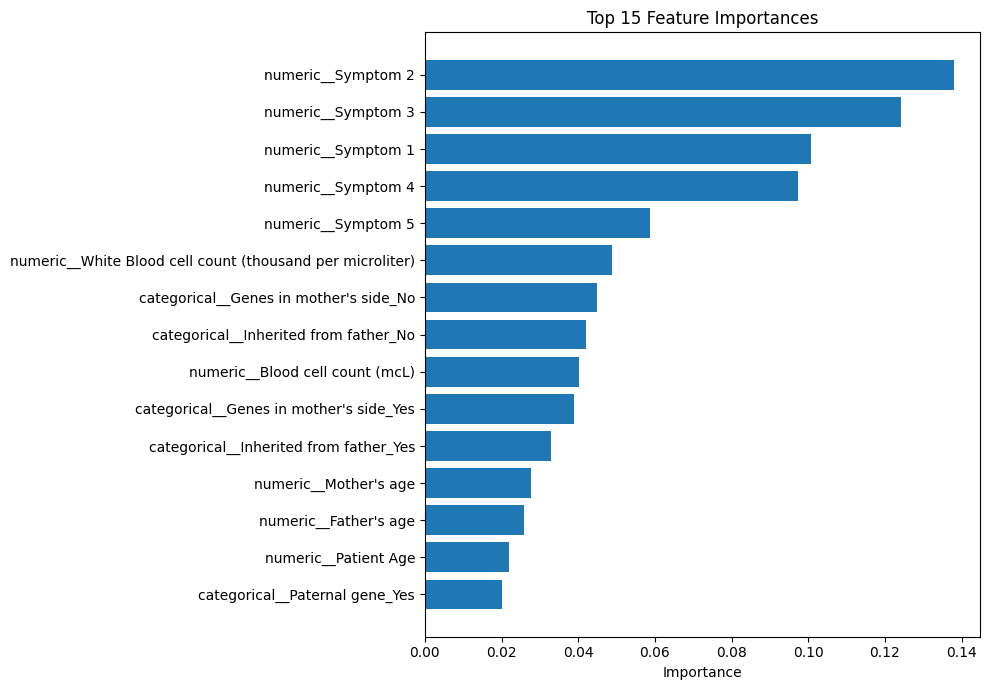

In [ ]:
# STEP 12: FEATURE IMPORTANCE

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_tree.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 important features:")
display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 13 — Explain an individual prediction**

In [ ]:
# STEP 13: EXPLAIN ONE PREDICTION

sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)[0]

preprocessor_fitted = best_model.named_steps["preprocessor"]
tree = best_model.named_steps["classifier"]

transformed_sample = preprocessor_fitted.transform(sample)
decision_path = tree.decision_path(transformed_sample)

node_ids = decision_path.indices
used_feature_indices = []

for node_id in node_ids:
    feature_index = tree.tree_.feature[node_id]

    if feature_index >= 0:
        used_feature_indices.append(feature_index)

# Remove duplicate feature names while preserving order
used_feature_indices = list(dict.fromkeys(used_feature_indices))

print("Predicted Genetic Disorder:", prediction)
print("\nFeatures used along the decision path:")

for index in used_feature_indices:
    print("-", feature_names[index])

if not used_feature_indices:
    print("No split feature was used for this prediction.")

Predicted Genetic Disorder: Mitochondrial genetic inheritance disorders

Features used along the decision path:
- numeric__Symptom 5
- numeric__Symptom 4
- numeric__Symptom 1
- numeric__Symptom 3
- numeric__Symptom 2
- categorical__Paternal gene_Yes
- categorical__Blood test result_normal
- categorical__Inherited from father_Yes


**Step 14 — Save the trained model**

In [ ]:
# STEP 14: SERIALIZE THE MODEL

artifact = {
    "model": best_model,
    "input_columns": list(X.columns),
    "target_classes": [str(c) for c in best_model.classes_],
    "feature_importance": importance_df.to_dict(orient="records"),
    "metrics": {
        "baseline_training_accuracy": float(
            accuracy_score(y_train, train_pred)
        ),
        "baseline_testing_accuracy": float(
            accuracy_score(y_test, test_pred)
        ),
        "tuned_training_accuracy": float(
            accuracy_score(y_train, best_train_pred)
        ),
        "tuned_testing_accuracy": float(
            accuracy_score(y_test, best_test_pred)
        ),
        "tuned_macro_f1": float(
            f1_score(y_test, best_test_pred, average="macro", zero_division=0)
        )
    }
}

joblib.dump(artifact, "genetic_disorder_model.joblib")

print("Model saved successfully!")
files.download("genetic_disorder_model.joblib")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 16: MOVE MODEL INTO PROJECT FOLDER

import os
import shutil

# Create folder if it does not exist
os.makedirs("/content/Genetic_Disorder_Project", exist_ok=True)

source = "/content/genetic_disorder_model.joblib"
destination = "/content/Genetic_Disorder_Project/genetic_disorder_model.joblib"

# Move the model file
if os.path.exists(source):
    shutil.move(source, destination)
    print("Model moved successfully!")
else:
    print("Model may already be in the project folder.")

Model moved successfully!


**Step 17 — Create flask_api.py**

In [ ]:
%%writefile /content/Genetic_Disorder_Project/flask_api.py

# STEP 17: FLASK BACKEND

from flask import Flask, request, jsonify
import joblib
import pandas as pd
import numpy as np
import os

app = Flask(__name__)

# Load the saved machine learning model
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    BASE_DIR, "genetic_disorder_model.joblib"
)

artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
input_columns = artifact["input_columns"]
metrics = artifact["metrics"]
feature_importance = artifact["feature_importance"]


# STEP 1: Home page API
@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "message": "Genetic Disorder Risk Assessment API is running"
    })


# STEP 2: Get model performance and feature importance
@app.route("/model-info", methods=["GET"])
def model_info():
    return jsonify({
        "metrics": metrics,
        "feature_importance": feature_importance[:15]
    })


# STEP 3: Predict genetic disorder
@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = request.get_json(silent=True)

        if not isinstance(data, dict):
            return jsonify({"error": "Send valid JSON data"}), 400

        features = data.get("features")

        if not isinstance(features, dict):
            return jsonify({
                "error": "Provide input inside the features field"
            }), 400

        # Prepare input in the same order used during training
        input_data = {
            col: features.get(col, np.nan)
            for col in input_columns
        }

        input_df = pd.DataFrame(
            [input_data],
            columns=input_columns
        )

        # Predict the disorder category
        prediction = str(model.predict(input_df)[0])

        # Explain the individual prediction
        preprocessor = model.named_steps["preprocessor"]
        tree = model.named_steps["classifier"]

        transformed = preprocessor.transform(input_df)
        path = tree.decision_path(transformed)

        feature_names = preprocessor.get_feature_names_out()
        used_features = []

        for node in path.indices:
            feature_index = tree.tree_.feature[node]

            if feature_index >= 0:
                feature_name = str(feature_names[feature_index])

                if feature_name not in used_features:
                    used_features.append(feature_name)

        return jsonify({
            "prediction": prediction,
            "important_features_for_this_prediction": used_features,
            "feature_importance": feature_importance[:15],
            "metrics": metrics,
            "notice": "Educational prototype only; not a medical diagnosis."
        })

    except Exception as error:
        return jsonify({
            "error": str(error)
        }), 400


# Start Flask server
if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)

Writing /content/Genetic_Disorder_Project/flask_api.py


**Step 18 — Install Flask**

In [ ]:
!pip install flask

**Step 19 — Check the backend**

In [ ]:
import sys

sys.path.insert(
    0,
    "/content/Genetic_Disorder_Project"
)

import flask_api

# Test the Flask API
client = flask_api.app.test_client()

response = client.get("/")

print("Status code:", response.status_code)
print("Response:", response.get_json())

Status code: 200
Response: {'message': 'Genetic Disorder Risk Assessment API is running'}


**Step 20 — Create streamlit_app.py**

In [ ]:
%%writefile /content/Genetic_Disorder_Project/streamlit_app.py

# STEP 20: STREAMLIT FRONTEND

import os
import requests
import joblib
import pandas as pd
import streamlit as st

# Project folder
BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# Load model information to build the input form
artifact = joblib.load(
    os.path.join(BASE_DIR, "genetic_disorder_model.joblib")
)

model = artifact["model"]
input_columns = artifact["input_columns"]

# Flask API address
API_URL = "http://127.0.0.1:5000"

# Page settings
st.set_page_config(
    page_title="Genetic Disorder Risk Assessment",
    page_icon="🧬",
    layout="wide"
)

# Page heading
st.title("🧬 Explainable Genetic Disorder Risk Assessment")
st.write(
    "An educational machine learning prototype using a Decision Tree Classifier."
)

st.info(
    "This application is for educational purposes only. "
    "It does not provide a medical diagnosis."
)

# Get numerical and categorical columns from the trained pipeline
preprocessor = model.named_steps["preprocessor"]

numeric_columns = []
categorical_columns = []

for name, transformer, columns in preprocessor.transformers_:
    if name == "numeric":
        numeric_columns = list(columns)
    elif name == "categorical":
        categorical_columns = list(columns)

# Read possible category values from the trained encoder
categorical_options = {}

if categorical_columns:
    categorical_pipeline = preprocessor.named_transformers_["categorical"]
    encoder = categorical_pipeline.named_steps["encoder"]

    for column, categories in zip(
        categorical_columns,
        encoder.categories_
    ):
        valid_categories = [
            str(value)
            for value in categories
            if pd.notna(value)
        ]

        categorical_options[column] = valid_categories or ["Unknown"]


# Input form
st.header("1. Enter Patient Information")
st.caption("Enter available information carefully. The form uses features from the training dataset.")

with st.form("prediction_form"):

    user_features = {}

    # Numerical inputs
    if numeric_columns:
        st.subheader("Numerical Features")

        numeric_cols = st.columns(2)

        for index, column in enumerate(numeric_columns):
            with numeric_cols[index % 2]:
                user_features[column] = st.number_input(
                    column,
                    value=0.0,
                    format="%.3f",
                    key=f"num_{index}"
                )

    # Categorical inputs
    if categorical_columns:
        st.subheader("Categorical Features")

        categorical_cols = st.columns(2)

        for index, column in enumerate(categorical_columns):
            options = categorical_options[column]

            with categorical_cols[index % 2]:
                user_features[column] = st.selectbox(
                    column,
                    options=options,
                    key=f"cat_{index}"
                )

    submitted = st.form_submit_button(
        "Predict Genetic Disorder",
        use_container_width=True
    )


# Prediction section
if submitted:

    with st.spinner("Connecting to the prediction API..."):

        try:
            response = requests.post(
                f"{API_URL}/predict",
                json={"features": user_features},
                timeout=60
            )

            if response.status_code == 200:

                result = response.json()

                st.header("2. Prediction Result")

                st.success(
                    f"Predicted Category: {result['prediction']}"
                )

                st.caption(result.get("notice", ""))

                # Features used for this individual prediction
                st.header("3. Important Features for This Prediction")

                used_features = result.get(
                    "important_features_for_this_prediction", []
                )

                if used_features:
                    for feature in used_features:
                        st.write("•", feature)
                else:
                    st.write("No split features were reported.")

                # Global feature importance
                st.header("4. Feature Importance")

                importance_data = result.get(
                    "feature_importance", []
                )

                if importance_data:
                    importance_df = pd.DataFrame(importance_data)

                    if not importance_df.empty:
                        importance_df = importance_df.sort_values(
                            "Importance", ascending=True
                        )

                        st.bar_chart(
                            importance_df.set_index("Feature")["Importance"]
                        )

                        st.dataframe(
                            importance_df.sort_values(
                                "Importance", ascending=False
                            ),
                            use_container_width=True
                        )

                # Decision tree visualization
                st.header("5. Decision Tree Visualization")

                tree_image = os.path.join(
                    BASE_DIR, "decision_tree.png"
                )

                if os.path.exists(tree_image):
                    st.image(
                        tree_image,
                        caption="Trained Decision Tree",
                        use_container_width=True
                    )
                else:
                    st.warning(
                        "decision_tree.png was not found in the project folder."
                    )

                # Model performance
                st.header("6. Model Performance")

                metrics = result.get("metrics", {})

                if metrics:
                    metric_cols = st.columns(3)

                    with metric_cols[0]:
                        st.metric(
                            "Training Accuracy",
                            f"{metrics.get('tuned_training_accuracy', 0) * 100:.2f}%"
                        )

                    with metric_cols[1]:
                        st.metric(
                            "Testing Accuracy",
                            f"{metrics.get('tuned_testing_accuracy', 0) * 100:.2f}%"
                        )

                    with metric_cols[2]:
                        st.metric(
                            "Macro F1 Score",
                            f"{metrics.get('tuned_macro_f1', 0):.3f}"
                        )

                    st.caption(
                        "Testing results measure performance on the held-out dataset; "
                        "they do not guarantee accuracy for an individual."
                    )

            else:
                st.error(
                    f"API error ({response.status_code}): "
                    f"{response.text}"
                )

        except requests.exceptions.ConnectionError:
            st.error(
                "Cannot connect to Flask. Start flask_api.py first, "
                "then run the Streamlit application."
            )

        except Exception as error:
            st.error(f"An error occurred: {error}")


# Footer
st.divider()
st.caption(
    "Educational prototype only. Feature importance indicates model usage, "
    "not proof of medical causation."
)


Writing /content/Genetic_Disorder_Project/streamlit_app.py


**Step 21 — Copy the Decision Tree image into the project folder**

In [ ]:
# STEP 21: COPY VISUALIZATION FILES

import os
import shutil

project_folder = "/content/Genetic_Disorder_Project"

for filename in ["decision_tree.png", "feature_importance.png"]:
    source = "/content/" + filename
    destination = os.path.join(project_folder, filename)

    if os.path.exists(source):
        shutil.copy(source, destination)
        print(filename, "copied successfully!")
    else:
        print(filename, "not found in /content")

decision_tree.png copied successfully!
feature_importance.png copied successfully!


**Step 22 — Install Streamlit and Requests**

In [ ]:
# STEP 22: INSTALL REQUIRED LIBRARIES

!pip install streamlit requests flask

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 18.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


**Step 23 — Flask backend test pannu**

In [ ]:
# STEP 23: TEST FLASK BACKEND

import sys
sys.path.insert(0, "/content/Genetic_Disorder_Project")

import flask_api

client = flask_api.app.test_client()

response = client.get("/")

print("Status:", response.status_code)
print(response.get_json())

**Step 24 — Check the project files**

In [ ]:
# STEP 24: CHECK PROJECT FILES

import os

folder = "/content/Genetic_Disorder_Project"

for filename in os.listdir(folder):
    print(filename)

feature_importance.png
__pycache__
streamlit_app.py
flask_api.py
genetic_disorder_model.joblib
decision_tree.png


**Step 25 — Start Flask backend**

In [ ]:
# STEP 25: START FLASK BACKEND

import subprocess
import sys
import os
import time

project_folder = "/content/Genetic_Disorder_Project"

flask_log = open("/content/flask_log.txt", "w")

flask_process = subprocess.Popen(
    [sys.executable, "flask_api.py"],
    cwd=project_folder,
    stdout=flask_log,
    stderr=subprocess.STDOUT
)

time.sleep(3)

print("Flask backend started!")
print("Backend address: http://127.0.0.1:5000")

Flask backend started!
Backend address: http://127.0.0.1:5000


**Step 26 — Start Streamlit frontend**

In [ ]:
# STEP 26: START STREAMLIT FRONTEND

import subprocess
import sys
import time

streamlit_log = open("/content/streamlit_log.txt", "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        "streamlit_app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd="/content/Genetic_Disorder_Project",
    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit frontend started!")

Streamlit frontend started!


**Step 27 — Open your frontend**

In [ ]:
# STEP 27: OPEN STREAMLIT IN BROWSER

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")

print("Open your Streamlit application:")
print(url)

Open your Streamlit application:
https://8501-m-s-usw1b6-3hmfbzasohhu2-b.us-west1.prod.r.colab.dev


In [ ]:
# CHECK STREAMLIT AND FLASK STATUS

import requests
import os

# Check Streamlit
try:
    r = requests.get("http://127.0.0.1:8501", timeout=5)
    print("Streamlit Status:", r.status_code)
except Exception as e:
    print("Streamlit Error:", e)

# Check Flask
try:
    r = requests.get("http://127.0.0.1:5000", timeout=5)
    print("Flask Status:", r.status_code)
    print("Flask Response:", r.text)
except Exception as e:
    print("Flask Error:", e)

# Check Streamlit log
print("\n--- STREAMLIT LOG ---")
if os.path.exists("/content/streamlit_log.txt"):
    print(open("/content/streamlit_log.txt").read()[-3000:])

In [ ]:
# CHECK SERVER PROCESS

!ps aux | grep -E 'streamlit|flask_api' | grep -v grep